# Parte 4 · ¿Quién sigue vivo?

**Autor:** José Gregorio Coronel Colombo · Grupo 1

**Declaración de uso de IA:** se utilizó inteligencia artificial como herramienta de apoyo para comprender lo que pedía cada inciso del enunciado y como asistencia al escribir y depurar el código. El análisis, la verificación de resultados y su interpretación fueron revisados por el autor.

**Referencias principales**

- Fader, P. S., Hardie, B. G. S. y Lee, K. L. (2005). "Counting Your Customers" the Easy Way: An Alternative to the Pareto/NBD Model. *Marketing Science*, 24(2), 275–284.
- Batislam, E. P., Denizel, M. y Filiztekin, A. (2007). Empirical Validation and Comparison of Models for Customer Base Analysis. *International Journal of Research in Marketing*, 24(3), 201–209.

Este notebook evalúa qué tan bien el BG/NBD identifica a los clientes que vuelven a comprar en el holdout (4.1–4.5) y lo compara con el MBG/NBD (4.6). Las funciones están en `src/bgnbd.py` (`p_vivo`, `p_compra`) y `src/mbgnbd.py`. Los parámetros del BG/NBD se leen de `resultados/params_cdnow.json`, que se sobrescribe con el ajuste oficial del inciso 2.1.

In [1]:
import sys, json, os, warnings
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, brier_score_loss
from datos import cargar_cdnow, resumen_clientes
from bgnbd import p_vivo, p_compra

trans = cargar_cdnow("../data/CDNOW_sample.txt")
res = resumen_clientes(trans, "1997-09-30", "1998-06-30")
x, tx, T = res["x"].values, res["tx"].values, res["T"].values
TAU = 39  # semanas de holdout: 1 oct 1997 – 30 jun 1998

RUTA_PARAMS = "../resultados/params_cdnow.json"
if os.path.exists(RUTA_PARAMS):
    params = json.load(open(RUTA_PARAMS))
    print("Parámetros de params_cdnow.json:", params)
else:
    params = {"r": 0.243, "alpha": 4.414, "a": 0.793, "b": 2.426}
    print("Aún no existe params_cdnow.json; se usan los del artículo:", params)

Parámetros de params_cdnow.json: {'r': 0.243, 'alpha': 4.414, 'a': 0.793, 'b': 2.426}


### Verificación de P(vivo) contra `lifetimes`

$P(\text{vivo})$ se programó a mano en `p_vivo`; `lifetimes` se usa solo para comprobar que da lo mismo con los mismos parámetros.

In [2]:
from lifetimes import BetaGeoFitter

bgf = BetaGeoFitter()
bgf.params_ = pd.Series(params)

res["p_vivo"] = p_vivo(x, tx, T, params)
print("Diferencia máxima con lifetimes:",
      f"{np.abs(res['p_vivo'] - bgf.conditional_probability_alive(x, tx, T)).max():.1e}")

Diferencia máxima con lifetimes: 2.2e-16


## 4.1 · P(vivo) como clasificador de Z

$Z_i = 1$ si el cliente $i$ compró al menos una vez en el holdout ($x^*_i \ge 1$). La tasa base es la fracción de clientes con $Z_i = 1$. Se clasifica como "vivo" a quien tiene $P(\text{vivo}) \ge 0.5$.

In [3]:
res["Z"] = (res["x_star"] >= 1).astype(int)
z = res["Z"].values
tasa_base = z.mean()
print(f"Tasa base: {tasa_base:.3f} ({z.sum()} de {len(z)} clientes compraron en el holdout)")

matriz = confusion_matrix(z, res["p_vivo"] >= 0.5)
auc_p_vivo = roc_auc_score(z, res["p_vivo"])
print(f"AUC de P(vivo): {auc_p_vivo:.3f}")
pd.DataFrame(matriz,
             index=["Real: no compró (Z = 0)", "Real: compró (Z = 1)"],
             columns=["Predicho: muerto (P < 0.5)", "Predicho: vivo (P ≥ 0.5)"])

Tasa base: 0.290 (684 de 2357 clientes compraron en el holdout)
AUC de P(vivo): 0.316


,Predicho: muerto (P < 0.5),Predicho: vivo (P ≥ 0.5)
Real: no compró (Z = 0),254,1419
Real: compró (Z = 1),139,545


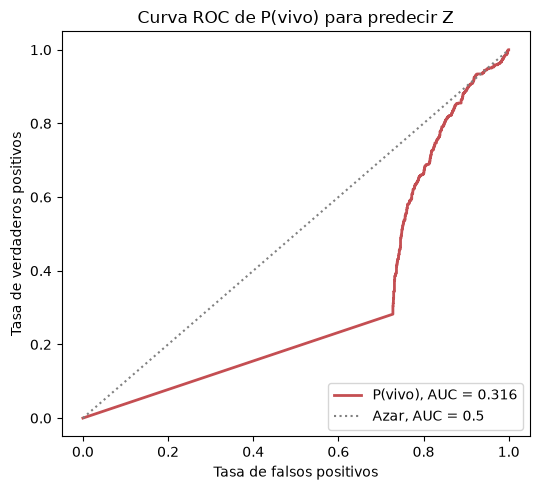

In [4]:
fpr, tpr, _ = roc_curve(z, res["p_vivo"])

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(fpr, tpr, color="#C44E52", lw=2, label=f"P(vivo), AUC = {auc_p_vivo:.3f}")
ax.plot([0, 1], [0, 1], color="gray", ls=":", label="Azar, AUC = 0.5")
ax.set(title="Curva ROC de P(vivo) para predecir Z", xlabel="Tasa de falsos positivos",
       ylabel="Tasa de verdaderos positivos")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../figs/parte4_roc_p_vivo.png", dpi=150)
plt.show()

> **Pregunta 4.1 (a).** ¿Cuál es la tasa base?

Solo el 29 % de los 2 357 clientes (684) realizó al menos una compra durante las 39 semanas de holdout. El 71 % restante no volvió a comprar.

> **Pregunta 4.1 (b).** ¿Qué tan bueno es P(vivo) como clasificador de Z?

Es muy malo. Con umbral 0.5, el modelo clasifica como vivos a 1 964 clientes, de los cuales 1 419 no compraron en el holdout. Por eso acierta apenas en ≈ 34 % de los casos, muy por debajo del 71 % que se obtendría prediciendo que nadie compra. El AUC es ≈ 0.32, **menor que 0.5**: ordenar a los clientes por $P(\text{vivo})$ funciona peor que ordenarlos al azar, porque quienes reciben la probabilidad más alta tienden a ser los que *menos* compran después.

## 4.2 · ¿Por qué el resultado es tan raro?

Se separa a los clientes que no hicieron compras repetidas en la calibración ($x = 0$) del resto.

In [5]:
res["grupo"] = np.where(res["x"] == 0, "x = 0", "x ≥ 1")
pd.DataFrame({
    "clientes": res.groupby("grupo").size(),
    "P(vivo) mínima": res.groupby("grupo")["p_vivo"].min(),
    "P(vivo) promedio": res.groupby("grupo")["p_vivo"].mean(),
    "fracción que compró en el holdout": res.groupby("grupo")["Z"].mean(),
}).round(3)

,clientes,P(vivo) mínima,P(vivo) promedio,fracción que compró en el holdout
grupo,,,,
x = 0,1411,1.0,1.000,0.137
x ≥ 1,946,0.0,0.535,0.519


> **Pregunta 4.2.** ¿Cuánto vale P(vivo) para un cliente con x = 0, y por qué? ¿Qué fracción de esos clientes compró en el holdout?

Para todo cliente con $x = 0$, $P(\text{vivo}) = 1$ exactamente, porque en la fórmula desaparece el término con $\delta_{x>0}$. La razón está en el supuesto 3 del BG/NBD: el cliente solo puede morir *justo después de una compra repetida*. Un cliente que solo hizo su primera compra nunca tuvo la oportunidad de morir, así que el modelo está seguro de que sigue vivo, sin importar cuánto tiempo lleve sin comprar.

Estos clientes son el 60 % de la base (1 411) y solo el ≈ 14 % de ellos compró en el holdout, la mitad de la tasa base. Por eso P(vivo) se equivoca tanto: el grupo al que asigna la máxima probabilidad es precisamente el que menos compra, lo que explica tanto los 1 419 falsos positivos como el AUC por debajo de 0.5. Además, aun si un cliente está vivo, puede tener una $\lambda$ tan baja que no compre en 39 semanas. Estar vivo no es lo mismo que comprar.

## 4.3 · La probabilidad correcta: P(Z = 1)

**Objetivo.** Mostrar que, con $\tau = 39$ semanas de holdout,

$$P(Z = 1 \mid x, t_x, T) = P(\text{vivo} \mid x, t_x, T)\left[1 - \left(\frac{\alpha + T}{\alpha + T + \tau}\right)^{r+x}\right].$$

**Paso 1: condicionar en si el cliente está vivo en $T$.** Por probabilidad total,

$$P(Z = 1 \mid x, t_x, T) = P(\text{vivo})\,P(Z = 1 \mid \text{vivo}) + P(\text{muerto})\,P(Z = 1 \mid \text{muerto}).$$

Un cliente muerto no vuelve a comprar, así que $P(Z = 1 \mid \text{muerto}) = 0$ y solo queda el primer término.

**Paso 2: un vivo que no compra sigue vivo.** En el BG/NBD la muerte solo puede ocurrir *inmediatamente después de una compra*. Por eso, para un cliente vivo en $T$, el evento "cero compras en $(T, T + \tau]$" depende solo de su proceso de Poisson: no puede morir antes de su siguiente compra. Si $\lambda$ fuera conocida,

$$P(\text{0 compras en } \tau \mid \lambda, \text{vivo}) = e^{-\lambda\tau}.$$

**Paso 3: posterior de $\lambda$ dado que está vivo.** Si el cliente sigue vivo en $T$, su historia pertenece a la rama (a) de 1.1, cuya verosimilitud en $\lambda$ es proporcional a $\lambda^x e^{-\lambda T}$ (el factor $(1-p)^x$ no depende de $\lambda$). Multiplicando por la previa $\text{Gamma}(r, \alpha)$:

$$f(\lambda \mid \text{vivo}, x, t_x, T) \;\propto\; \lambda^x e^{-\lambda T}\cdot \lambda^{r-1}e^{-\alpha\lambda} = \lambda^{r+x-1}e^{-(\alpha+T)\lambda},$$

es decir, $\lambda \mid \text{vivo}, \text{datos} \sim \text{Gamma}(r + x,\ \alpha + T)$.

**Paso 4: mezcla gamma–Poisson.** Se integra $e^{-\lambda\tau}$ contra esa posterior:

$$P(\text{0 compras en } \tau \mid \text{vivo}) = \int_0^\infty e^{-\lambda\tau}\,\frac{(\alpha+T)^{r+x}\lambda^{r+x-1}e^{-(\alpha+T)\lambda}}{\Gamma(r+x)}\,d\lambda = \frac{(\alpha+T)^{r+x}}{\Gamma(r+x)}\cdot\frac{\Gamma(r+x)}{(\alpha+T+\tau)^{r+x}} = \left(\frac{\alpha+T}{\alpha+T+\tau}\right)^{r+x}.$$

Es la misma integral de 1.2, con $\alpha + T + \tau$ en lugar de $\alpha + s$.

**Resultado.** $P(Z = 1 \mid \text{vivo}) = 1 - \left(\frac{\alpha+T}{\alpha+T+\tau}\right)^{r+x}$. Al sustituir en el paso 1 se obtiene la fórmula. $\blacksquare$

**Para una diapositiva:** $P(Z=1) = \underbrace{P(\text{vivo})}_{\text{¿sigue activo?}}\times\underbrace{\left[1 - \left(\tfrac{\alpha+T}{\alpha+T+\tau}\right)^{r+x}\right]}_{\text{¿compra en } \tau \text{ si está activo?}}$. Para $x = 0$ el primer factor vale 1, pero el segundo es pequeño porque la posterior $\text{Gamma}(r, \alpha + T)$ concentra $\lambda$ cerca de 0: un cliente que lleva $T$ semanas sin repetir probablemente compra muy poco.

La fórmula está implementada en `p_compra(tau, x, tx, T, params)` de `src/bgnbd.py`. La siguiente celda muestra los dos factores por grupo.

In [6]:
res["p_compra"] = p_compra(TAU, x, tx, T, params)
res.groupby("grupo")[["p_vivo", "p_compra", "Z"]].mean().round(3).rename(columns={
    "p_vivo": "P(vivo) promedio", "p_compra": "P(Z = 1) promedio", "Z": "fracción que compró"})

,P(vivo) promedio,P(Z = 1) promedio,fracción que compró
grupo,,,
x = 0,1.000,0.161,0.137
x ≥ 1,0.535,0.413,0.519


## 4.4 · Verificación de P(Z = 1) por simulación

Se simulan 50 000 clientes con `simular_clientes` (`src/simulacion.py`) usando los parámetros estimados, con $T \sim \text{Uniforme}(27, 39)$ y `horizonte_extra=39` para simular también el holdout (semilla 85967). Para cada cliente simulado se calcula `p_compra(39, ...)`. Después se forman deciles de esa probabilidad y en cada uno se compara el promedio de la probabilidad con la fracción de clientes que de verdad compró en el holdout simulado. Si la fórmula es correcta, los dos valores deben coincidir salvo por el error Monte Carlo.

In [7]:
from simulacion import simular_clientes


def tabla_deciles(prob, z):
    # rank(method="first") rompe empates para que cada decil tenga el mismo número de clientes
    decil = pd.qcut(pd.Series(prob).rank(method="first"), 10, labels=range(1, 11))
    t = pd.DataFrame({"prob": np.asarray(prob), "z": np.asarray(z)}).groupby(decil.values, observed=True)
    out = pd.DataFrame({"clientes": t.size(), "P(Z = 1) promedio": t["prob"].mean(),
                        "fracción que compró": t["z"].mean()})
    out.index.name = "decil"
    return out


sim = simular_clientes(50_000, params, np.random.default_rng(85967), horizonte_extra=TAU)
sim["p_compra"] = p_compra(TAU, sim["x"], sim["tx"], sim["T"], params)
sim["Z"] = (sim["x_star"] >= 1).astype(int)

cal_sim = tabla_deciles(sim["p_compra"], sim["Z"])
cal_sim["error estándar MC"] = np.sqrt(cal_sim["P(Z = 1) promedio"] * (1 - cal_sim["P(Z = 1) promedio"]) / cal_sim["clientes"])
cal_sim["diferencia"] = cal_sim["fracción que compró"] - cal_sim["P(Z = 1) promedio"]
print(f"Promedio global: fórmula {sim['p_compra'].mean():.4f} | simulación {sim['Z'].mean():.4f}")
cal_sim.round(4)

Promedio global: fórmula 0.2600 | simulación 0.2615


,clientes,P(Z = 1) promedio,fracción que compró,error estándar MC,diferencia
decil,,,,,
1,5000,0.1182,0.1122,0.0046,-0.0060
2,5000,0.1489,0.1528,0.0050,0.0039
3,5000,0.1539,0.1584,0.0051,0.0045
4,5000,0.1590,0.1628,0.0052,0.0038
5,5000,0.1647,0.1634,0.0052,-0.0013
6,5000,0.1706,0.1754,0.0053,0.0048
7,5000,0.1849,0.1978,0.0055,0.0129
8,5000,0.3107,0.3088,0.0065,-0.0019
9,5000,0.4502,0.4480,0.0070,-0.0022


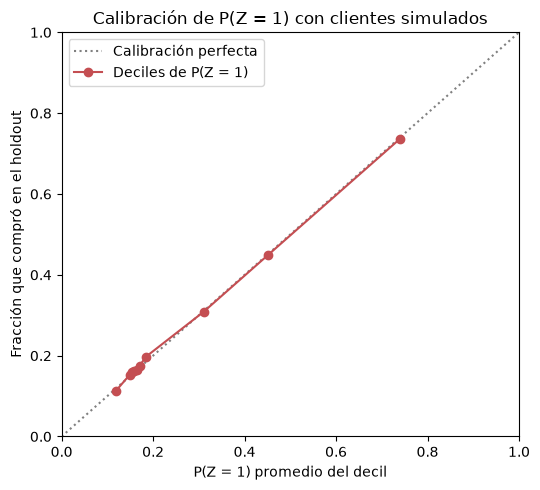

In [8]:
def grafica_calibracion(tabla, titulo, archivo):
    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.plot([0, 1], [0, 1], color="gray", ls=":", label="Calibración perfecta")
    ax.plot(tabla["P(Z = 1) promedio"], tabla["fracción que compró"], color="#C44E52",
            marker="o", label="Deciles de P(Z = 1)")
    ax.set(title=titulo, xlabel="P(Z = 1) promedio del decil", ylabel="Fracción que compró en el holdout",
           xlim=(0, 1), ylim=(0, 1))
    ax.legend(loc="upper left")
    plt.tight_layout()
    plt.savefig(f"../figs/{archivo}", dpi=150)
    plt.show()


grafica_calibracion(cal_sim, "Calibración de P(Z = 1) con clientes simulados", "parte4_calibracion_simulada.png")

> **Pregunta 4.4.** ¿La simulación confirma la fórmula de 4.3?

Sí. En los diez deciles, la fracción simulada que compra coincide con la probabilidad promedio de la fórmula. Las diferencias están dentro de unos dos errores estándar Monte Carlo (≈ 0.005); solo el decil 7 se aleja un poco más (≈ 0.013), lo que es esperable entre diez comparaciones. Además, no siguen ningún patrón: no hay deciles sistemáticamente por encima ni por debajo de la diagonal. El promedio global también coincide. Como los datos se generaron con los mismos supuestos del modelo, este resultado verifica la derivación y el código de `p_compra`, no el ajuste del modelo a CDNOW. Eso se evalúa en 4.5.

## 4.5 · P(Z = 1) sobre los datos reales

Se compara $P(Z = 1)$ contra dos puntajes que no necesitan modelo: la **recencia** $t_x$ (mientras más alto, más reciente fue la última compra) y la **frecuencia** $x$. Como estos puntajes no son probabilidades, para ellos solo se reporta el AUC. El Brier score de $P(Z = 1)$ se compara contra el de asignar la tasa base a todos los clientes.

In [9]:
puntajes = {"P(Z = 1) del BG/NBD": res["p_compra"], "Recencia tx": res["tx"], "Frecuencia x": res["x"]}
auc = {k: roc_auc_score(z, v) for k, v in puntajes.items()}
brier = {"P(Z = 1) del BG/NBD": brier_score_loss(z, res["p_compra"]),
         "Tasa base para todos": brier_score_loss(z, np.full(len(z), tasa_base))}

display(pd.Series(auc, name="AUC").to_frame().round(3))
pd.Series(brier, name="Brier score").to_frame().round(4)

,AUC
P(Z = 1) del BG/NBD,0.757
Recencia tx,0.763
Frecuencia x,0.758


,Brier score
P(Z = 1) del BG/NBD,0.1612
Tasa base para todos,0.2060


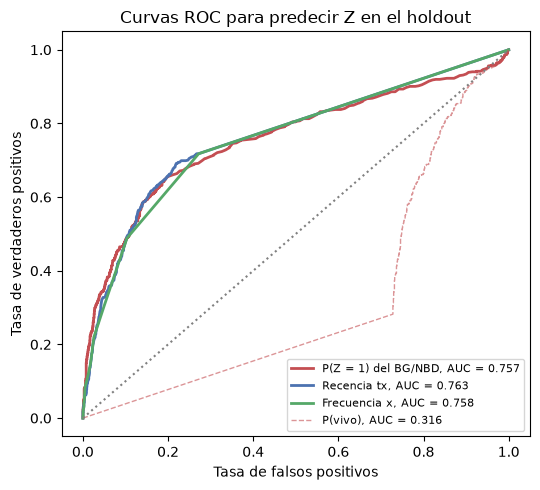

In [10]:
fig, ax = plt.subplots(figsize=(5.5, 5))
colores = {"P(Z = 1) del BG/NBD": "#C44E52", "Recencia tx": "#4C72B0", "Frecuencia x": "#55A868"}
for nombre, v in puntajes.items():
    f, t, _ = roc_curve(z, v)
    ax.plot(f, t, color=colores[nombre], lw=2, label=f"{nombre}, AUC = {auc[nombre]:.3f}")
ax.plot(fpr, tpr, color="#C44E52", ls="--", lw=1, alpha=0.6, label=f"P(vivo), AUC = {auc_p_vivo:.3f}")
ax.plot([0, 1], [0, 1], color="gray", ls=":")
ax.set(title="Curvas ROC para predecir Z en el holdout", xlabel="Tasa de falsos positivos",
       ylabel="Tasa de verdaderos positivos")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("../figs/parte4_roc_comparacion.png", dpi=150)
plt.show()

,clientes,P(Z = 1) promedio,fracción que compró,diferencia
decil,,,,
1,236,0.122,0.199,0.077
2,236,0.150,0.097,-0.053
3,235,0.155,0.136,-0.019
4,236,0.160,0.114,-0.046
5,236,0.165,0.161,-0.004
6,235,0.171,0.170,-0.000
7,236,0.181,0.237,0.056
8,235,0.304,0.438,0.134
9,236,0.467,0.534,0.066


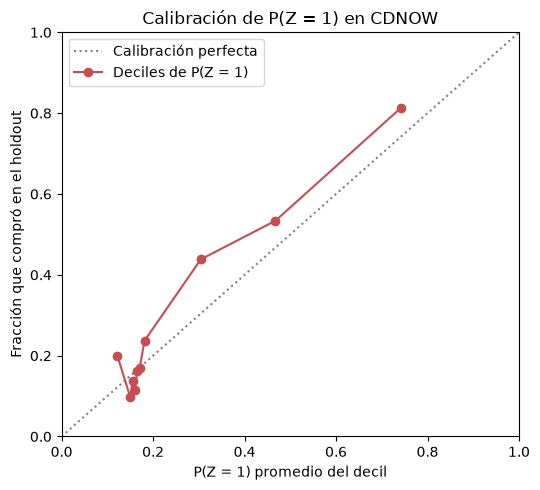

In [11]:
cal_real = tabla_deciles(res["p_compra"], z)
cal_real["diferencia"] = cal_real["fracción que compró"] - cal_real["P(Z = 1) promedio"]
display(cal_real.round(3))
grafica_calibracion(cal_real, "Calibración de P(Z = 1) en CDNOW", "parte4_calibracion_real.png")

> **Pregunta 4.5 (a).** ¿P(Z = 1) está bien calibrada en los datos reales?

En términos generales, sí. Su Brier score (≈ 0.161) es ≈ 22 % menor que el de predecir la tasa base a todos (≈ 0.206), aunque en promedio el modelo se queda algo corto: $P(Z=1)$ promedia ≈ 0.26 frente a una tasa base de 0.29. Por deciles, los siete inferiores, compuestos en su mayoría por clientes con $x = 0$, tienen probabilidades entre 0.12 y 0.18 y fracciones reales en el mismo rango, aunque con más ruido que en la simulación. En cambio, en los tres deciles superiores el modelo **subestima** sistemáticamente: predice ≈ 0.30, 0.47 y 0.74, mientras que compraron ≈ 0.44, 0.53 y 0.81. Es la misma subestimación de los clientes repetidores que Sofía encontró en 3.4, cuando el BG/NBD se quedaba corto en los grupos de x = 1 y x = 2.

> **Pregunta 4.5 (b).** Siendo honestos: ¿el modelo ordena a los clientes mejor que una sola variable? Si no, ¿qué ofrece que esas variables no?

No. El AUC de $P(Z = 1)$ (≈ 0.757) es prácticamente igual al de la frecuencia $x$ (≈ 0.758) y ligeramente menor que el de la recencia $t_x$ (≈ 0.763). Para ordenar a los clientes de más a menos probable de volver a comprar, basta con ordenarlos por la fecha de su última compra.

Lo que el modelo ofrece y esas variables no:

1. **Probabilidades calibradas.** $t_x$ y $x$ solo ordenan. $P(Z=1)$ dice *cuánto* vale cada cliente (por ejemplo, 0.15 contra 0.74), lo que permite calcular el número esperado de compradores, comparar contra el costo de una promoción o fijar un umbral con sentido económico.
2. **Cualquier horizonte $\tau$.** La misma fórmula da la probabilidad de comprar en 4, 13 o 52 semanas sin reajustar nada. Un puntaje como $t_x$ es el mismo para cualquier horizonte.
3. **No necesita etiquetas.** El BG/NBD se ajusta solo con los datos de calibración. Para convertir $t_x$ o $x$ en probabilidades habría que observar antes un holdout y ajustar, por ejemplo, una regresión logística (la Parte 6).
4. **Un solo marco.** Los mismos cuatro parámetros dan $E[X(t)]$, $E[Y(\tau)]$, $P(\text{vivo})$ y $P(Z = 1)$, es decir, pronóstico agregado e individual de forma coherente.

## 4.6 · Otro miembro de la familia: el MBG/NBD

El MBG/NBD (Batislam et al., 2007) cambia una sola pieza del BG/NBD: el cliente **también puede morir justo después de su primera compra**. En la verosimilitud de 1.1 esto agrega un factor $(1-p)$ a la rama "sigue vivo" y permite la rama "murió en $t_x$" incluso con $x = 0$ (con $t_x = 0$). Al integrar sobre $p$, los argumentos de la función beta se corren en uno: $B(a, b+x+1)$ y $B(a+1, b+x)$. Además desaparece $\delta_{x>0}$:

$$L = \frac{\Gamma(r+x)\,\alpha^r}{\Gamma(r)}\left[\frac{B(a, b+x+1)}{B(a,b)}\frac{1}{(\alpha+T)^{r+x}} + \frac{B(a+1, b+x)}{B(a,b)}\frac{1}{(\alpha+t_x)^{r+x}}\right].$$

En `src/mbgnbd.py`, la verosimilitud se ajusta con el mismo optimizador de `ajustar_bgnbd` (tres arranques, Nelder–Mead y L-BFGS-B). También están implementadas $P(\text{vivo})$, $P(Z=1)$, $E[X(t)]$ y $E[Y(\tau)]$ del enunciado.

In [12]:
from bgnbd import NOMBRES, loglik_bgnbd, esperado_X, esperado_Y
from mbgnbd import (ajustar_mbgnbd, p_vivo_mbgnbd, p_compra_mbgnbd,
                    esperado_X_mbgnbd, esperado_Y_mbgnbd)
from lifetimes import ModifiedBetaGeoFitter

params_mbg = ajustar_mbgnbd(x, tx, T)
ll_mbg = params_mbg.pop("ll")
ll_bg = loglik_bgnbd(np.log([params[k] for k in NOMBRES]), x, tx, T)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    mbgf = ModifiedBetaGeoFitter().fit(x, tx, T)

pd.DataFrame({
    "BG/NBD (params_cdnow.json)": [params[k] for k in NOMBRES] + [ll_bg],
    "MBG/NBD (src/mbgnbd.py)": [params_mbg[k] for k in NOMBRES] + [ll_mbg],
    "MBG/NBD (lifetimes)": list(mbgf.params_[list(NOMBRES)]) + [np.nan],
}, index=list(NOMBRES) + ["LL"]).round(4)

,BG/NBD (params_cdnow.json),MBG/NBD (src/mbgnbd.py),MBG/NBD (lifetimes)
r,0.2430,0.5248,0.5248
alpha,4.4140,6.1831,6.1831
a,0.7930,0.8914,0.8914
b,2.4260,1.6140,1.6140
LL,-9582.4305,-9582.1357,NaN


In [13]:
t_prueba = np.array([1, 5, 13, 26, 39, 78])
pd.DataFrame({
    "función": ["E[X(t)], t = 1…78", "E[Y(39) | x, tx, T]", "P(vivo | x, tx, T)"],
    "diferencia máxima con lifetimes": [
        np.abs(esperado_X_mbgnbd(t_prueba, params_mbg) - mbgf.expected_number_of_purchases_up_to_time(t_prueba)).max(),
        np.abs(esperado_Y_mbgnbd(TAU, x, tx, T, params_mbg)
               - mbgf.conditional_expected_number_of_purchases_up_to_time(TAU, x, tx, T)).max(),
        np.abs(p_vivo_mbgnbd(x, tx, T, params_mbg) - mbgf.conditional_probability_alive(x, tx, T)).max(),
    ],
})

,función,diferencia máxima con lifetimes
0,"E[X(t)], t = 1…78",2.027241e-07
1,"E[Y(39) | x, tx, T]",1.629114e-06
2,"P(vivo | x, tx, T)",1.104428e-07


### Comparación con el BG/NBD

El total del holdout se calcula de dos formas:

- **Bottom-up de la cohorte**, igual que en 3.1: suma de $E[X(w - s_i)]$ por semana, con el mismo cálculo de Sofía, para que el número del BG/NBD coincida con su tabla de 3.3.
- **Condicional:** $\sum_i E[Y(39) \mid x_i, t_{x,i}, T_i]$ contra $\sum_i x^*_i$.

In [14]:
from datos import serie_semanal_repetidas

res["p_vivo_mbg"] = p_vivo_mbgnbd(x, tx, T, params_mbg)
res["p_compra_mbg"] = p_compra_mbgnbd(TAU, x, tx, T, params_mbg)

# mismo cálculo que 03_pronostico (3.1) para que el total del BG/NBD coincida con la tabla de Sofía
semanas = np.arange(1, 79)
dt = semanas[:, None] - res["semana_primera"].values[None, :]


def total_holdout(f_ex, p):
    acum = np.where(dt > 0, f_ex(np.clip(dt, 0, None), p), 0).sum(axis=1)
    return acum[77] - acum[38]


real_holdout = serie_semanal_repetidas(trans, 78).iloc[39:].sum()
cero = res["x"] == 0
comparacion = pd.DataFrame({
    "BG/NBD": [ll_bg, res.loc[cero, "p_vivo"].mean(), auc_p_vivo, auc["P(Z = 1) del BG/NBD"],
               brier["P(Z = 1) del BG/NBD"], total_holdout(esperado_X, params),
               esperado_Y(TAU, x, tx, T, params).sum()],
    "MBG/NBD": [ll_mbg, res.loc[cero, "p_vivo_mbg"].mean(), roc_auc_score(z, res["p_vivo_mbg"]),
                roc_auc_score(z, res["p_compra_mbg"]), brier_score_loss(z, res["p_compra_mbg"]),
                total_holdout(esperado_X_mbgnbd, params_mbg),
                esperado_Y_mbgnbd(TAU, x, tx, T, params_mbg).sum()],
    "Real": [np.nan, np.nan, np.nan, np.nan, np.nan, real_holdout, res["x_star"].sum()],
}, index=["Log-verosimilitud", "P(vivo) promedio con x = 0", "AUC de P(vivo)", "AUC de P(Z = 1)",
          "Brier de P(Z = 1)", "Total holdout, bottom-up (sem 40–78)", "Total holdout, Σ E[Y(39)]"])
comparacion["error MBG vs real (%)"] = (comparacion["MBG/NBD"] - comparacion["Real"]) / comparacion["Real"] * 100
comparacion["error BG vs real (%)"] = (comparacion["BG/NBD"] - comparacion["Real"]) / comparacion["Real"] * 100
comparacion.round(3)

,BG/NBD,MBG/NBD,Real,error MBG vs real (%),error BG vs real (%)
Log-verosimilitud,-9582.430,-9582.136,NaN,NaN,NaN
P(vivo) promedio con x = 0,1.000,0.409,NaN,NaN,NaN
AUC de P(vivo),0.316,0.687,NaN,NaN,NaN
AUC de P(Z = 1),0.757,0.760,NaN,NaN,NaN
Brier de P(Z = 1),0.161,0.161,NaN,NaN,NaN
"Total holdout, bottom-up (sem 40–78)",1666.291,1571.660,1882.0,-16.490,-11.462
"Total holdout, Σ E[Y(39)]",1653.941,1576.728,1882.0,-16.221,-12.118


In [15]:
print(f"P(vivo) del MBG/NBD con x = 0: entre {res.loc[cero, 'p_vivo_mbg'].min():.3f} y "
      f"{res.loc[cero, 'p_vivo_mbg'].max():.3f}; compró en el holdout el {res.loc[cero, 'Z'].mean():.1%}")
print("Correlación de Spearman entre P(Z = 1) de ambos modelos:",
      f"{res[['p_compra', 'p_compra_mbg']].corr(method='spearman').iloc[0, 1]:.3f}")
top = int(0.2 * len(res))
comunes = len(set(res.nlargest(top, "p_compra").index) & set(res.nlargest(top, "p_compra_mbg").index))
print(f"Clientes en común entre el 20 % con mayor P(Z = 1) de cada modelo: {comunes} de {top}")

P(vivo) del MBG/NBD con x = 0: entre 0.390 y 0.428; compró en el holdout el 13.7%
Correlación de Spearman entre P(Z = 1) de ambos modelos: 0.976
Clientes en común entre el 20 % con mayor P(Z = 1) de cada modelo: 464 de 471


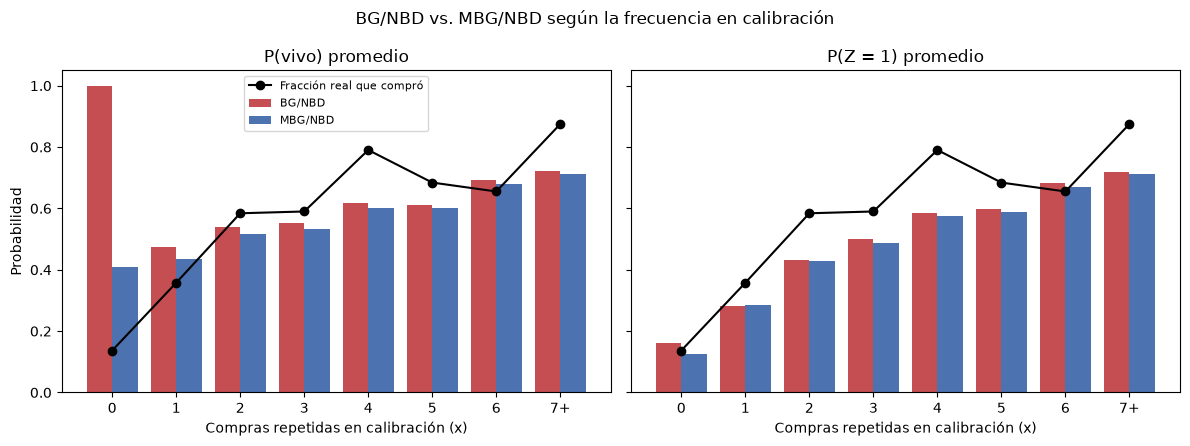

In [16]:
res["grupo_x"] = np.minimum(res["x"], 7)
por_x = res.groupby("grupo_x")[["p_vivo", "p_vivo_mbg", "p_compra", "p_compra_mbg", "Z"]].mean()
etiquetas = [str(i) if i < 7 else "7+" for i in por_x.index]
pos = np.arange(len(por_x))

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for eje, (col_bg, col_mbg, titulo) in zip(ejes, [("p_vivo", "p_vivo_mbg", "P(vivo) promedio"),
                                                  ("p_compra", "p_compra_mbg", "P(Z = 1) promedio")]):
    eje.bar(pos - 0.2, por_x[col_bg], width=0.4, color="#C44E52", label="BG/NBD")
    eje.bar(pos + 0.2, por_x[col_mbg], width=0.4, color="#4C72B0", label="MBG/NBD")
    eje.plot(pos, por_x["Z"], color="black", marker="o", label="Fracción real que compró")
    eje.set_xticks(pos, etiquetas)
    eje.set(title=titulo, xlabel="Compras repetidas en calibración (x)")
ejes[0].set_ylabel("Probabilidad")
ejes[0].legend(fontsize=8)
fig.suptitle("BG/NBD vs. MBG/NBD según la frecuencia en calibración")
plt.tight_layout()
plt.savefig("../figs/parte4_bgnbd_vs_mbgnbd.png", dpi=150)
plt.show()

> **Pregunta 4.6 (a).** ¿Cómo se comparan los dos modelos?

- **Ajuste.** Las log-verosimilitudes son prácticamente iguales (≈ −9 582.1 para el MBG/NBD frente a ≈ −9 582.4 para el BG/NBD), con el mismo número de parámetros. Una diferencia de 0.3 en LL es despreciable, así que los datos de calibración no permiten distinguir entre ambos modelos. Los parámetros sí cambian: el MBG/NBD estima una $r$ y una $\alpha$ mayores, y una $b$ menor (≈ 1.61 contra ≈ 2.43), lo que implica una mayor probabilidad de morir por compra, porque ahora también se puede morir después de la primera compra.
- **P(vivo) con x = 0.** Deja de valer 1 y queda entre ≈ 0.39 y 0.43. Es más razonable, aunque todavía muy superior al 14 % que compró. Con este cambio, el AUC de $P(\text{vivo})$ pasa de ≈ 0.32 a ≈ 0.69: el MBG/NBD corrige el problema de 4.2.
- **P(Z = 1).** Los AUC son casi idénticos (≈ 0.757 y ≈ 0.760) y también los Brier (≈ 0.161 en ambos casos). Los dos modelos ordenan a los clientes prácticamente igual: la correlación de Spearman entre sus $P(Z=1)$ es muy alta y comparten casi todo el 20 % superior.
- **Total del holdout.** Ambos modelos subestiman, pero el MBG/NBD lo hace más: ≈ 1 572 frente a ≈ 1 666 del BG/NBD, contra 1 882 reales (≈ −16 % y ≈ −12 %, respectivamente). Al permitir más muertes, el MBG/NBD es más pesimista sobre la actividad futura.

> **Pregunta 4.6 (b).** ¿Por qué la fórmula de 4.3 sigue valiendo en el MBG/NBD?

Porque los dos argumentos de la derivación no cambian. (1) En el MBG/NBD el cliente también muere *solo justo después de una compra* (ahora incluida la primera), así que un cliente vivo que no compra sigue vivo, y la probabilidad de cero compras en $\tau$ depende solo de $\lambda$. (2) Dado que el cliente está vivo, la verosimilitud de su historia sigue siendo proporcional a $\lambda^x e^{-\lambda T}$: el factor adicional $(1-p)$ no depende de $\lambda$, así que la posterior sigue siendo $\text{Gamma}(r + x, \alpha + T)$ y el segundo factor es el mismo. Lo único que cambia es $P(\text{vivo})$, que se reemplaza por la versión del MBG/NBD. Por eso `p_compra_mbgnbd` reusa `p_compra_si_vivo` de `src/bgnbd.py`.

> **Pregunta 4.6 (c).** Si los dos modelos ajustan casi igual de bien, ¿con cuál se quedan para decidir a qué clientes mandarles una promoción?

Para decidir a quién mandar la promoción, lo correcto es usar $P(Z=1)$, no $P(\text{vivo})$, y con esa medida los dos modelos escogen prácticamente a los mismos clientes. Aun así, nos quedaríamos con el **MBG/NBD**. Su $P(\text{vivo})$ no comete el error de considerar seguro que siguen activos los clientes que compraron una sola vez. Estos clientes son el 60 % de la base, y es justamente el grupo en el que una promoción de reactivación tendría sentido. Con el BG/NBD, si alguien usa por error $P(\text{vivo})$ como criterio, termina enviando la promoción sobre todo a quienes menos compran. Con igual ajuste y la misma capacidad para ordenar, conviene el modelo cuyas probabilidades no engañan.

La salvedad es que, para pronosticar el **total** de compras (por ejemplo, para planear inventario), el BG/NBD se acercó más al valor real en este holdout. Si el objetivo fuera ese, usaríamos el BG/NBD. Además, ninguno de los dos supera a la recencia $t_x$ para ordenar a los clientes (4.5).